In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("grocerydb.csv")

df.head()

,name,store,category,brand,FPro,FPro_class,price,price percal,package_weight,Protein,Total Fat,Carbohydrate,"Sugars, total","Fiber, total dietary",Sodium,Cholesterol
0,Stonyfield Organic Whole Milk Strawberry Beet ...,Target,baby-food,Stonyfield,0.815250,3.0,5.29,0.043984,396.8930,5.050505,3.030303,12.121212,9.090909,0.000000,0.080808,0.010101
1,Stonyfield Organic Whole Milk Pear Spinach Man...,Target,baby-food,Stonyfield,0.815250,3.0,5.29,0.043984,396.8930,5.050505,3.030303,12.121212,9.090909,0.000000,0.080808,0.010101
2,Once Upon a Farm Organic Mama Blueberry Fruit ...,Target,baby-food,Once Upon a Farm,0.583219,3.0,2.79,0.055973,90.7184,1.098901,0.549451,13.186813,7.692308,2.197802,0.010989,0.000000
3,Once Upon a Farm Organic Strawberry Kids&#39; ...,Target,baby-food,Once Upon a Farm,0.451056,0.0,2.49,0.019213,90.7184,5.494505,7.692308,15.384615,8.791209,3.296703,0.000000,0.000000
4,Horizon Organic Growing Years Strawberry Kids&...,Target,baby-food,DANNON,0.773519,3.0,4.99,0.017781,396.8930,3.030303,1.010101,14.141414,6.060606,2.020202,0.050505,0.005051


In [5]:
df.shape

(26250, 16)

In [6]:
df.columns.tolist()

['name',
 'store',
 'category',
 'brand',
 'FPro',
 'FPro_class',
 'price',
 'price percal',
 'package_weight',
 'Protein',
 'Total Fat',
 'Carbohydrate',
 'Sugars, total',
 'Fiber, total dietary',
 'Sodium',
 'Cholesterol']

My topic is ultra-processed foods dominate all three grocery chains.

In [7]:
df["store"].value_counts()

store
WholeFoods    10851
Walmart        8896
Target         6503
Name: count, dtype: int64

In [8]:
df["FPro_class"].value_counts(dropna=False)

FPro_class
3.0    19895
0.0     3313
2.0     2426
1.0      616
Name: count, dtype: int64

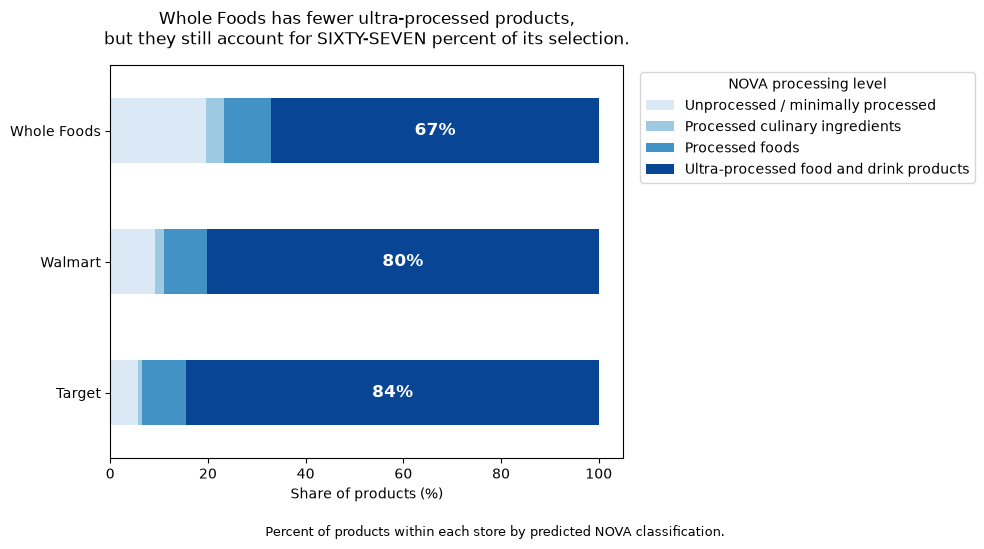

In [23]:
plot_data = pd.crosstab(
    df["store"],
    df["FPro_class"],
    normalize="index"
) * 100

# Rename store for display
plot_data = plot_data.rename(index={"WholeFoods": "Whole Foods"})

colors = ["#dbe9f6", "#9ecae1", "#4292c6", "#084594"]
ax = plot_data.plot(
    kind="barh",
    stacked=True,
    figsize=(10, 5.5),
    color=colors
)

ax.set_xlabel("Share of products (%)")
ax.set_ylabel("")

ax.set_title(
    "Whole Foods has fewer ultra-processed products,\n"
    "but they still account for SIXTY-SEVEN percent of its selection.",
    pad=15
)

ax.legend(
    title="NOVA processing level",
    labels=[
        "Unprocessed / minimally processed",
        "Processed culinary ingredients",
        "Processed foods",
        "Ultra-processed food and drink products"
    ],
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

# Add labels for ultra-processed share
for i, store in enumerate(plot_data.index):
    ultra = plot_data.loc[store, 3.0]

    ax.text(
        100 - ultra / 2,
        i,
        f"{ultra:.0f}%",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        color="white"
    )

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.figtext(
    0.5,
    0.015,
    "Percent of products within each store by predicted NOVA classification.",
    ha="center",
    fontsize=9
)
plt.savefig("project1_plot.png", dpi=300, bbox_inches="tight")

plt.show()

I wanted to compare food processing levels across Whole Foods, Walmart, and Target. Whole Foods is often associated with higher-quality or less processed food, so I wanted to see whether that pattern appears in the dataset. The result shows that Whole Foods has fewer ultra-processed products than the other two stores, although they still make up 67% of its selection.  
I used a 100% stacked horizontal bar chart so the processing-level proportions can be compared directly across stores. The blue shades become darker as the NOVA processing level increases, and the ultra-processed percentages are labeled directly because they are the main takeaway.  
I grouped products by store and FPro_class, then converted the counts to percentages within each store. During development, I tested several nutrition-related ideas before choosing this comparison because it produced a clearer and more interpretable pattern.